# Кредитный риск: анализ данных German Credit

**Команда №** _[номер команды]_

| Участник | Группа |
|---|---|
| _[Фамилия Имя]_ | _[номер группы]_ |
| _[Фамилия Имя]_ | _[номер группы]_ |
| _[Фамилия Имя]_ | _[номер группы]_ |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.weightstats import ztest
from statsmodels.stats.proportion import proportions_ztest
from sklearn.preprocessing import StandardScaler, LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

sns.set_theme(style='whitegrid')

## Описание данных

- **Тема:** кредитный риск — по характеристикам заёмщика и кредита определить, будет ли заёмщик «хорошим» (вернёт кредит) или «плохим».
- **Наблюдение:** один заёмщик немецкого банка (одна выданная кредитная заявка).
- **Источник:** German Credit Data, UCI Machine Learning Repository (проф. Hans Hofmann), упрощённая версия с Kaggle (`german_credit_data.csv`) с добавленной целевой переменной `target`.

In [2]:
df_raw = pd.read_excel('german_credit_data_final.xlsx')
df_raw.head()

,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,target
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,1
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,2
2,2,49,male,1,own,little,NaN,2096,12,education,1
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,1
4,4,53,male,2,free,little,little,4870,24,car,2


In [3]:
print('Наблюдений:', df_raw.shape[0])
print('Признаков:', df_raw.shape[1])

Наблюдений: 1000
Признаков: 11


В таблице **1000 наблюдений и 11 столбцов**. Первый столбец `Unnamed: 0` — это сохранённый индекс строки, а не признак заёмщика, поэтому удаляем его: остаётся **10 признаков** (9 предикторов + целевой `target`).

In [4]:
df = df_raw.drop(columns='Unnamed: 0')
df.shape

(1000, 10)

## Описание признаков

In [5]:
df.dtypes

Age                 int64
Sex                   str
Job                 int64
Housing               str
Saving accounts       str
Checking account      str
Credit amount       int64
Duration            int64
Purpose               str
target              int64
dtype: object

| Признак | Описание | Формат данных | Тип данных |
|---|---|---|---|
| `Age` | Возраст заёмщика, лет | int64 | количественный дискретный |
| `Sex` | Пол заёмщика (male / female) | object | категориальный бинарный |
| `Job` | Квалификация: 0 — неквалифицированный нерезидент, 1 — неквалифицированный резидент, 2 — квалифицированный, 3 — высококвалифицированный | int64 | категориальный порядковый |
| `Housing` | Жильё: own (своё), rent (аренда), free (бесплатное) | object | категориальный номинальный |
| `Saving accounts` | Сбережения: little < moderate < quite rich < rich | object | категориальный порядковый |
| `Checking account` | Остаток на текущем счёте: little < moderate < rich | object | категориальный порядковый |
| `Credit amount` | Сумма кредита, немецкие марки | int64 | количественный непрерывный |
| `Duration` | Срок кредита, месяцев | int64 | количественный дискретный |
| `Purpose` | Цель кредита (car, radio/TV, education и т.д.) | object | категориальный номинальный |
| `target` | Кредитный риск: 1 — хороший заёмщик, 2 — плохой | int64 | категориальный бинарный (**целевой**) |

*Примечание:* в pandas ≥ 3.0 текстовые столбцы показываются в `dtypes` как `str`, в pandas 2.x — как `object`; это один и тот же текстовый формат.
`Job` хранится числами, но это коды категорий: разница между 3 и 2 не равна разнице между 1 и 0, поэтому признак порядковый, а не количественный.

## Пропуски и дубликаты

In [6]:
df.isna().sum()

Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
target                0
dtype: int64

Пропуски есть в двух признаках: `Saving accounts` (183) и `Checking account` (394). Оба признака категориальные, поэтому подходящая мера центральной тенденции — **мода** (среднее и медиану для текстовых категорий посчитать нельзя).

In [7]:
df_clean = df.copy()
for col in ['Saving accounts', 'Checking account']:
    mode_value = df_clean[col].mode()[0]
    print(col, '-> мода:', mode_value)
    df_clean[col] = df_clean[col].fillna(mode_value)

df_clean.isna().sum().sum()

Saving accounts -> мода: little
Checking account -> мода: little


np.int64(0)

In [8]:
print('Полных дубликатов:', df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()
df_clean.shape

Полных дубликатов: 0


(1000, 10)

- Пропуски заполнены модой `little` в обоих признаках. Ограничение: в `Checking account` пропусков почти 40%, и в исходном датасете они, скорее всего, означают «нет текущего счёта», поэтому после заполнения доля `little` завышена.
- Полных дубликатов нет (проверка сделана **после** удаления `Unnamed: 0`, иначе уникальный номер строки скрыл бы дубликаты).
- Очищенные данные сохранены в `df_clean` — 1000 строк.

## Выбросы

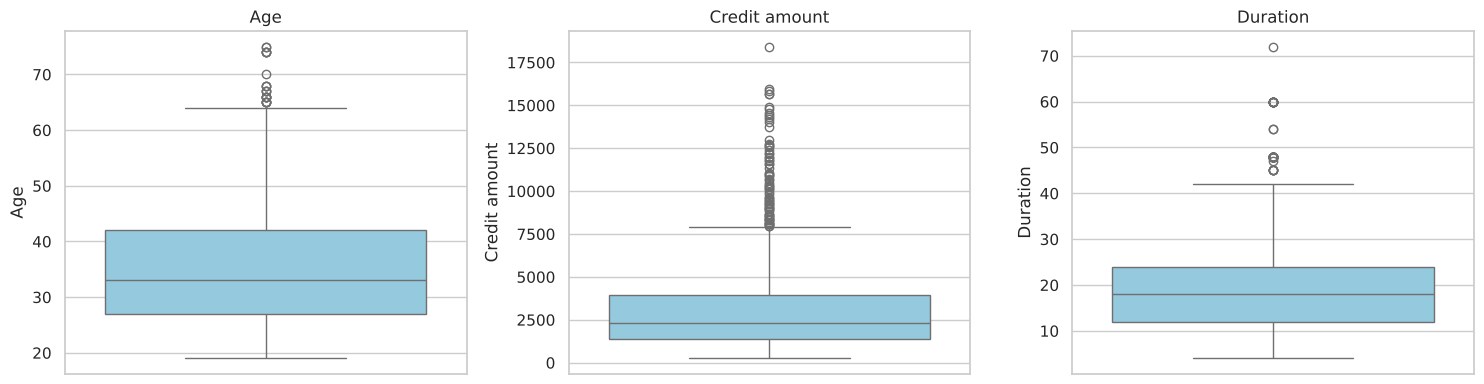

In [9]:
num_cols = ['Age', 'Credit amount', 'Duration']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df_clean[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

Выбросы (точки за усами) видны во всех трёх количественных признаках, сверху: пожилые заёмщики, очень крупные кредиты и очень длинные сроки. Сильнее всего выделяется `Credit amount`.

### Метод 3 стандартных отклонений (`Credit amount`)

Наблюдение считается выбросом, если оно отстоит от среднего больше чем на 3σ.

In [10]:
mean_ca = df_clean['Credit amount'].mean()
std_ca = df_clean['Credit amount'].std()
lower, upper = mean_ca - 3 * std_ca, mean_ca + 3 * std_ca
print(f'Границы: [{lower:.1f}; {upper:.1f}]')

df_sigma = df_clean[(df_clean['Credit amount'] >= lower) & (df_clean['Credit amount'] <= upper)]
print('Было:', len(df_clean), 'Стало:', len(df_sigma), 'Удалено:', len(df_clean) - len(df_sigma))

Границы: [-5197.0; 11739.5]
Было: 1000 Стало: 975 Удалено: 25


### Метод 1.5·IQR (`Duration`)

Работаем с `df_sigma`. Выброс — значение вне интервала [Q1 − 1.5·IQR; Q3 + 1.5·IQR].

In [11]:
q1 = df_sigma['Duration'].quantile(0.25)
q3 = df_sigma['Duration'].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f'Q1 = {q1}, Q3 = {q3}, IQR = {iqr}, границы: [{lower}; {upper}]')

df_iqr = df_sigma[(df_sigma['Duration'] >= lower) & (df_sigma['Duration'] <= upper)]
print('Было:', len(df_sigma), 'Стало:', len(df_iqr), 'Удалено:', len(df_sigma) - len(df_iqr))

Q1 = 12.0, Q3 = 24.0, IQR = 12.0, границы: [-6.0; 42.0]
Было: 975 Стало: 917 Удалено: 58


- Методом 3σ удалено 25 кредитов дороже ≈ 11 739 марок.
- Методом 1.5·IQR удалено 58 кредитов сроком больше 42 месяцев.
- Дальше работаем с `df_iqr` — **917 наблюдений**.

## Визуализация

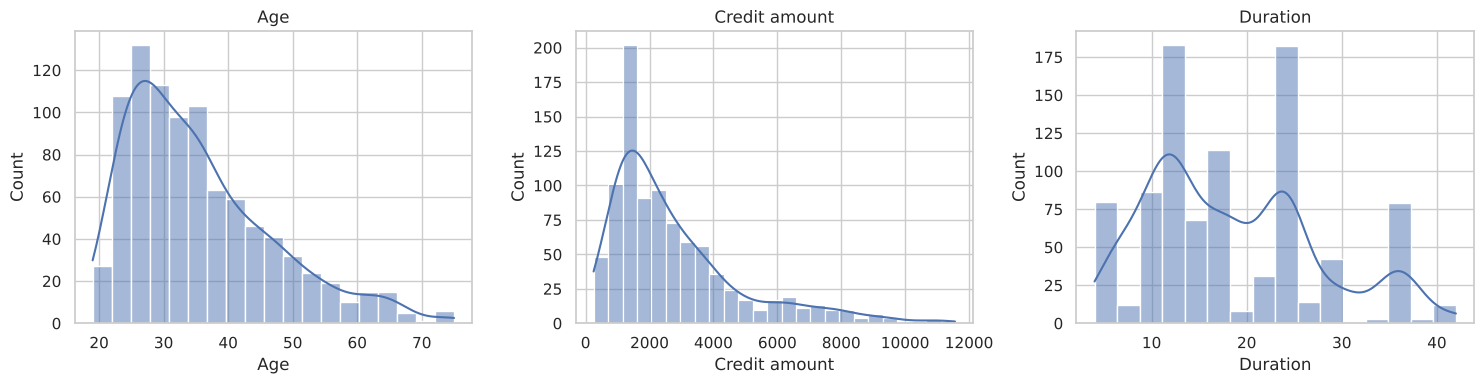

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df_iqr[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Выводы по количественным признакам:**
- `Age` — распределение скошено вправо: основная масса заёмщиков 25–40 лет, пожилых мало. Не нормальное.
- `Credit amount` — сильная правосторонняя асимметрия: большинство кредитов до 4000 марок, крупные встречаются редко. Не нормальное.
- `Duration` — значения сгруппированы на «круглых» сроках (12, 18, 24, 36 месяцев), чаще всего 12 и 24 месяца; распределение тоже скошено вправо.

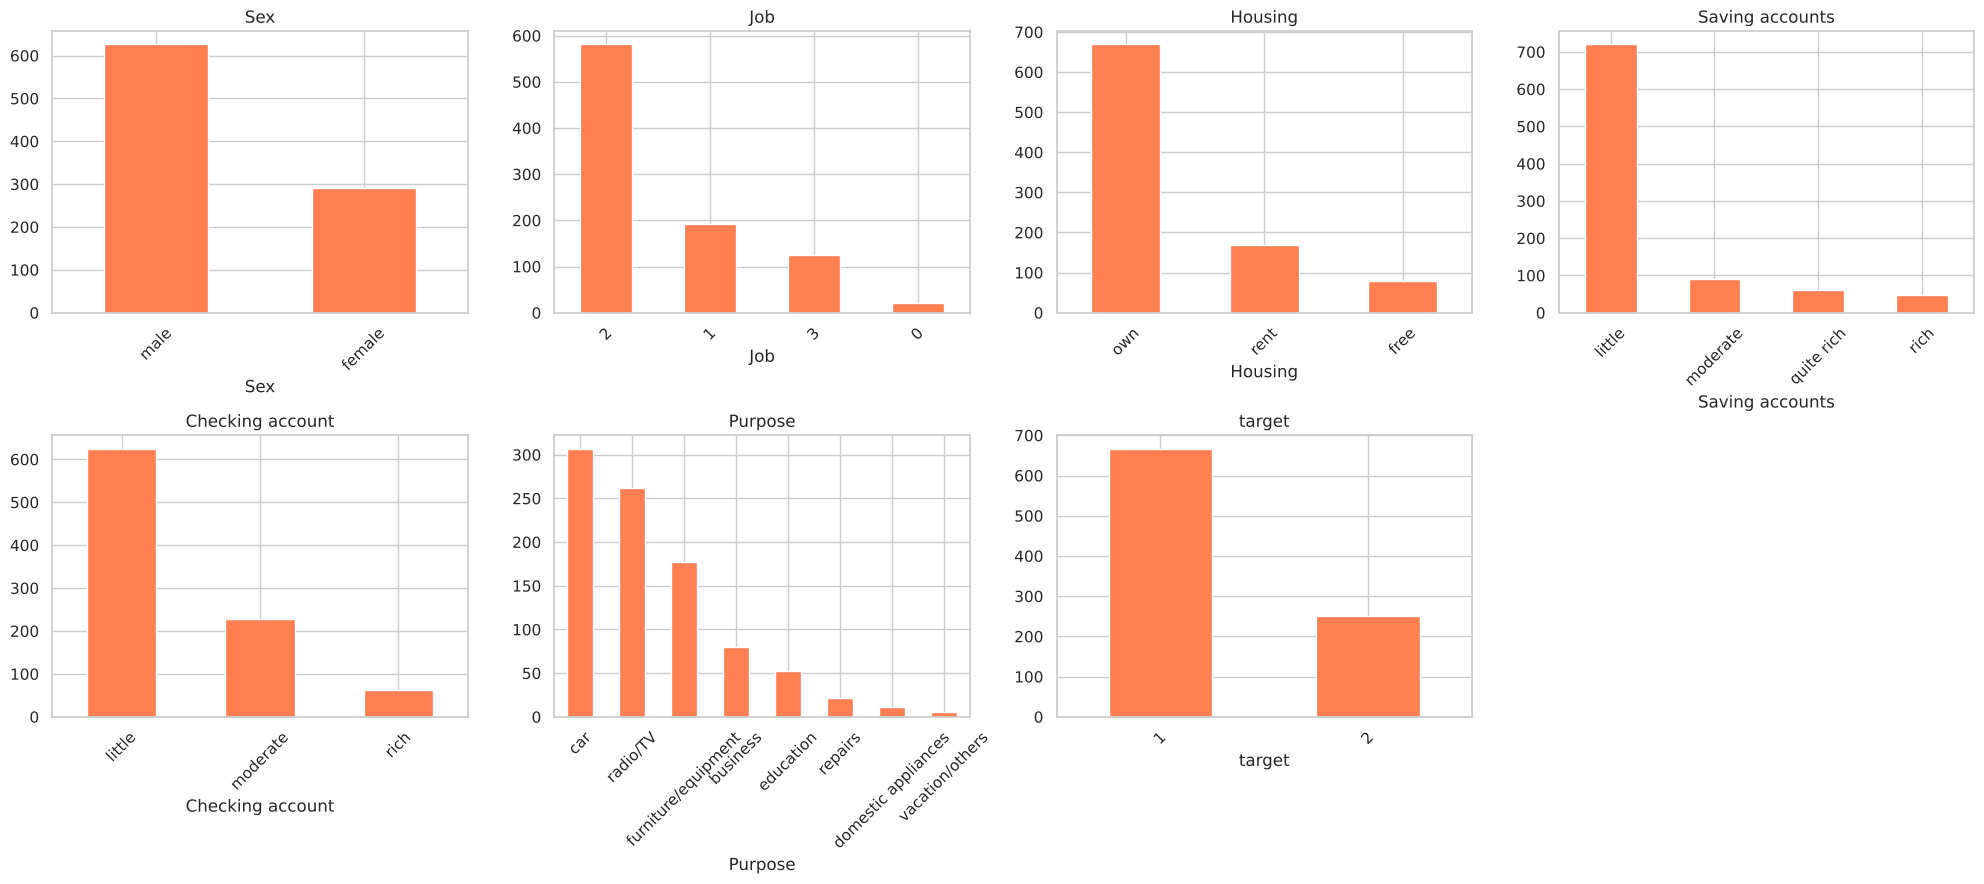

In [13]:
cat_cols = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose', 'target']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, col in zip(axes.flat, cat_cols):
    df_iqr[col].value_counts().plot(kind='bar', ax=ax, color='coral')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.show()

**Выводы по категориальным признакам:**
- `Sex` — мужчин больше двух третей (≈ 68%).
- `Job` — преобладают квалифицированные работники (код 2, ≈ 63%), неквалифицированных нерезидентов (0) всего ≈ 2%.
- `Housing` — ≈ 73% живут в собственном жилье.
- `Saving accounts` и `Checking account` — после заполнения пропусков доминирует `little` (≈ 79% и ≈ 68%).
- `Purpose` — чаще всего берут кредит на автомобиль (≈ 34%) и радио/ТВ (≈ 29%); отпуск и бытовая техника — редкие цели.
- `target` — классы несбалансированы: хороших заёмщиков ≈ 73%, плохих ≈ 27%.

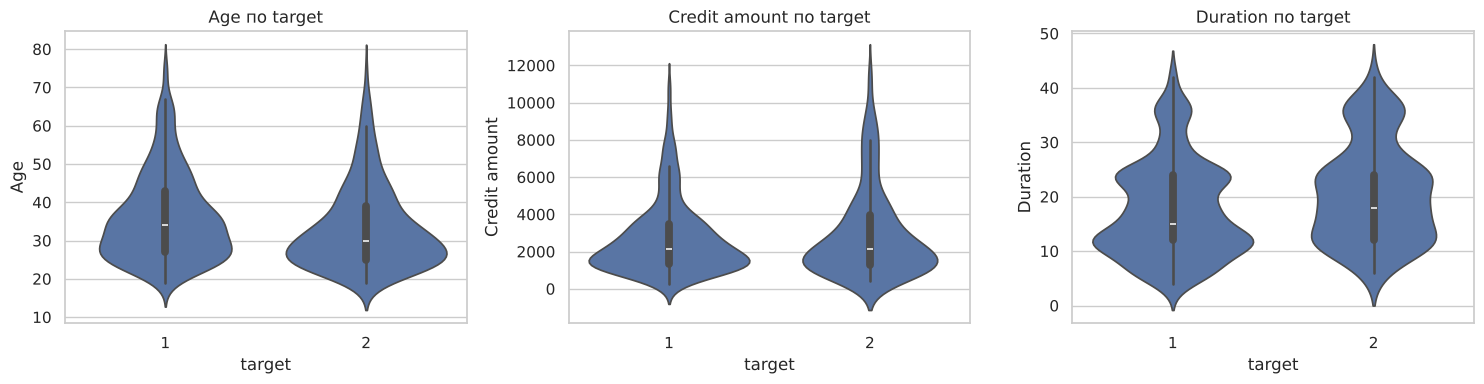

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.violinplot(data=df_iqr, x='target', y=col, ax=ax)
    ax.set_title(f'{col} по target')
plt.tight_layout()
plt.show()

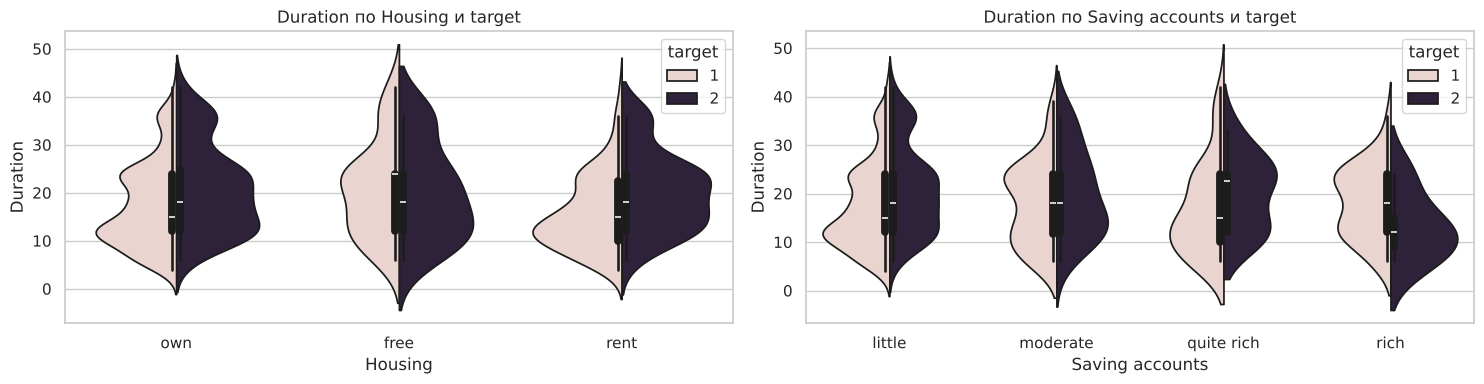

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.violinplot(data=df_iqr, x='Housing', y='Duration', hue='target', split=True, ax=axes[0])
axes[0].set_title('Duration по Housing и target')
sns.violinplot(data=df_iqr, x='Saving accounts', y='Duration', hue='target', split=True,
               order=['little', 'moderate', 'quite rich', 'rich'], ax=axes[1])
axes[1].set_title('Duration по Saving accounts и target')
plt.tight_layout()
plt.show()

In [16]:
df_iqr.groupby('target')[num_cols].median()

,Age,Credit amount,Duration
target,,,
1,34.0,2134.0,15.0
2,30.0,2134.5,18.0


**Выводы по скрипичным графикам:**
- `Duration` — у плохих заёмщиков распределение сдвинуто к более длинным срокам (медиана 18 мес. против 15 у хороших): чем дольше кредит, тем выше риск.
- `Age` — плохие заёмщики в среднем моложе (медиана 30 лет против 34), их распределение сильнее сосредоточено в 20–30 годах.
- `Credit amount` — формы распределений почти совпадают (медианы ≈ 2134 у обеих групп): после удаления выбросов сумма кредита слабо отличает хороших заёмщиков от плохих.
- `Housing` — у арендаторов и владельцев жилья плохие заёмщики берут кредиты на более длинный срок (медиана 18 против 15 мес.); у живущих бесплатно (`free`) наоборот — у хороших заёмщиков медианный срок больше (24 против 18 мес.), но эта группа малочисленна (79 человек).
- `Saving accounts` — при малых сбережениях (`little`) плохие заёмщики берут кредиты на более долгий срок; у богатых (`rich`) плохих заёмщиков мало, и их распределение неустойчиво.

## Описательные статистики

### Целевой признак

`target` — бинарный категориальный признак, поэтому для него считаем частоты, доли и моду. Среднее по кодам 1/2 смысла не имеет.

In [17]:
target_stats = pd.DataFrame({
    'Частота': df_iqr['target'].value_counts(),
    'Доля': df_iqr['target'].value_counts(normalize=True).round(3)
})
print('Мода:', df_iqr['target'].mode()[0])
target_stats

Мода: 1


,Частота,Доля
target,,
1,667,0.727
2,250,0.273


**Интерпретация:**
- Мода равна 1: типичный заёмщик в выборке — «хороший».
- Хороших заёмщиков 667 (≈ 72.7%), плохих — 250 (≈ 27.3%).
- Классы несбалансированы (примерно 3 : 1). Модель, которая всегда отвечает «хороший», уже даёт ≈ 73% правильных ответов, поэтому при оценке регрессии одной accuracy недостаточно.

### Предикторы

In [18]:
num_desc = df_iqr[num_cols].describe().T
num_desc['median'] = df_iqr[num_cols].median()
num_desc['IQR'] = num_desc['75%'] - num_desc['25%']
num_desc['skew'] = df_iqr[num_cols].skew()
num_desc.round(2)

,count,mean,std,min,25%,50%,75%,max,median,IQR,skew
Age,917.0,35.47,11.37,19.0,27.0,33.0,42.0,75.0,33.0,15.0,1.04
Credit amount,917.0,2776.10,2074.85,250.0,1318.0,2134.0,3556.0,11560.0,2134.0,2238.0,1.58
Duration,917.0,18.56,9.02,4.0,12.0,18.0,24.0,42.0,18.0,12.0,0.60


In [19]:
cat_pred = ['Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account', 'Purpose']
df_iqr[cat_pred].astype(str).describe().T

,count,unique,top,freq
Sex,917,2,male,626
Job,917,4,2,581
Housing,917,3,own,669
Saving accounts,917,4,little,720
Checking account,917,3,little,625
Purpose,917,8,car,307


**Интерпретация количественных предикторов:**
- `Age`: средний возраст ≈ 35.5 года, медиана 33; среднее больше медианы — правосторонняя асимметрия (skew ≈ 1.04). Половина заёмщиков в возрасте от 27 до 42 лет (IQR = 15).
- `Credit amount`: средняя сумма ≈ 2776 марок, медиана 2134. Большой разрыв между ними и skew ≈ 1.58 говорят о сильной асимметрии, поэтому типичный кредит лучше описывает медиана. Стандартное отклонение (≈ 2075) сопоставимо со средним — разброс большой.
- `Duration`: средний срок ≈ 18.6 мес., медиана 18, мода 24; половина кредитов выдана на срок от 12 до 24 месяцев. Асимметрия умеренная (skew ≈ 0.6).

**Интерпретация категориальных предикторов** (для них используются мода и частоты):
- Мода `Sex` — male (≈ 68%), `Housing` — own (≈ 73%), `Purpose` — car (≈ 34%; всего 8 уникальных целей).
- Мода `Job` — 2 (квалифицированный работник). Для порядкового признака можно указать и медиану: она тоже 2.
- Мода `Saving accounts` и `Checking account` — little: у большинства заёмщиков небольшие сбережения и остатки на счетах.

## Перекодирование данных

Работаем с очищенными данными `df_iqr`. Целевую переменную переводим в формат 0/1, где **1 — плохой заёмщик** (событие, которое мы хотим предсказывать), 0 — хороший.

In [20]:
df_enc = df_iqr.copy()
df_enc['target'] = df_enc['target'].map({1: 0, 2: 1})
df_enc['target'].value_counts()

target
0    667
1    250
Name: count, dtype: int64

### One-Hot: бинарный признак `Sex`

In [21]:
df_enc = pd.get_dummies(df_enc, columns=['Sex'], drop_first=True, dtype=int)
df_enc[['Sex_male']].head()

,Sex_male
0,1
2,1
3,1
4,1
5,1


`drop_first=True` оставляет один столбец `Sex_male` (1 — мужчина, 0 — женщина). Второй столбец был бы лишним: он однозначно восстанавливается из первого.

### LabelEncoder: номинальные `Purpose` и `Housing`

In [22]:
le_purpose = LabelEncoder()
df_enc['Purpose'] = le_purpose.fit_transform(df_enc['Purpose'])
print(dict(zip(le_purpose.classes_, le_purpose.transform(le_purpose.classes_))))

le_housing = LabelEncoder()
df_enc['Housing'] = le_housing.fit_transform(df_enc['Housing'])
print(dict(zip(le_housing.classes_, le_housing.transform(le_housing.classes_))))

{'business': np.int64(0), 'car': np.int64(1), 'domestic appliances': np.int64(2), 'education': np.int64(3), 'furniture/equipment': np.int64(4), 'radio/TV': np.int64(5), 'repairs': np.int64(6), 'vacation/others': np.int64(7)}
{'free': np.int64(0), 'own': np.int64(1), 'rent': np.int64(2)}


LabelEncoder присваивает номера категориям по алфавиту, поэтому сами числа не несут смысла «больше/меньше».

### OrdinalEncoder: порядковые `Saving accounts` и `Checking account`

In [23]:
oe = OrdinalEncoder(categories=[['little', 'moderate', 'quite rich', 'rich'],
                                ['little', 'moderate', 'rich']])
df_enc[['Saving accounts', 'Checking account']] = oe.fit_transform(
    df_enc[['Saving accounts', 'Checking account']])
df_enc[['Saving accounts', 'Checking account']].value_counts().head()

Saving accounts  Checking account
0.0              0.0                 499
                 1.0                 170
                 2.0                  51
1.0              0.0                  49
2.0              0.0                  46
Name: count, dtype: int64

Порядок категорий задан явно (little = 0 < moderate = 1 < quite rich = 2 < rich = 3), иначе OrdinalEncoder упорядочил бы их по алфавиту и нарушил бы смысл шкалы.

In [24]:
df_enc.head()

,Age,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,target,Sex_male
0,67,2,1,0.0,0.0,1169,6,5,0,1
2,49,1,1,0.0,0.0,2096,12,3,0,1
3,45,2,0,0.0,0.0,7882,42,4,0,1
4,53,2,0,0.0,0.0,4870,24,1,1,1
5,35,1,0,0.0,0.0,9055,36,3,0,1


## Корреляция

### Парная корреляция: `target` и `Duration`

`target` бинарный, `Duration` количественный, поэтому используем **точечно-бисериальную корреляцию** (частный случай корреляции Пирсона для бинарной переменной).

In [25]:
r, p = stats.pointbiserialr(df_enc['target'], df_enc['Duration'])
print(f'r = {r:.3f}, p-value = {p:.2e}')

r = 0.155, p-value = 2.30e-06


**Интерпретация:**
- r ≈ 0.155 > 0: связь **прямая** — чем длиннее срок кредита, тем чаще заёмщик оказывается плохим (target = 1).
- По модулю коэффициент меньше 0.3, связь **слабая**: срок объясняет лишь небольшую часть различий между заёмщиками.
- p-value ≈ 2.3·10⁻⁶ < 0.05, поэтому связь статистически значима: на 5%-м уровне отвергаем гипотезу об отсутствии корреляции.

### Корреляционная матрица

Используем коэффициент **Спирмена**: он оценивает монотонную связь и подходит для порядковых (`Job`, `Saving accounts`, `Checking account`) и бинарных признаков, а также устойчив к асимметрии распределений.

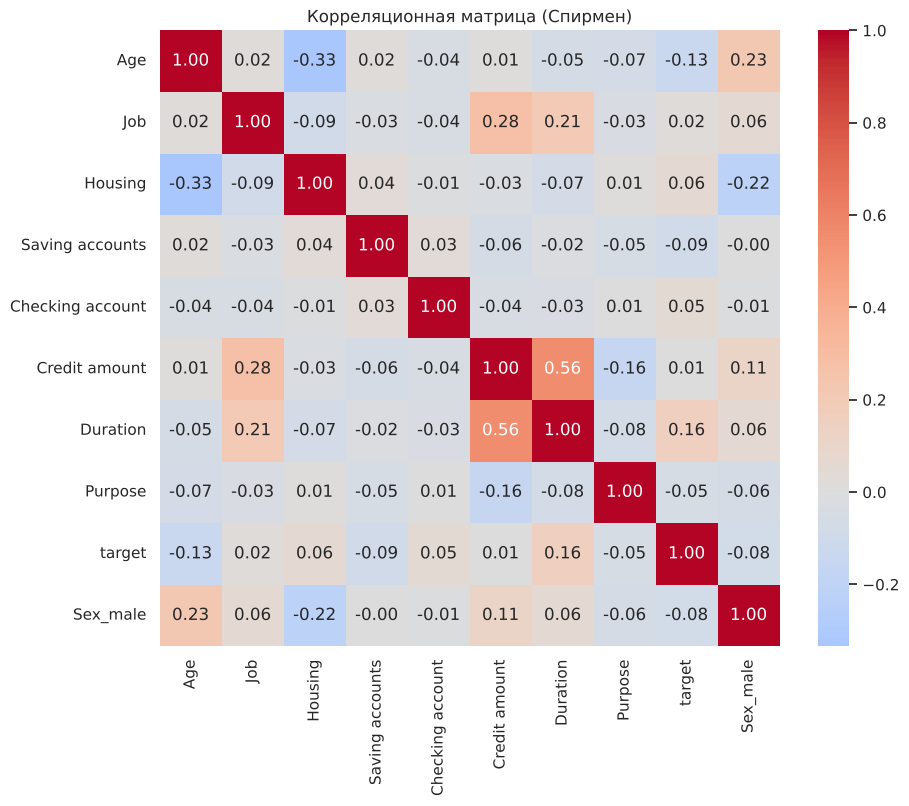

In [26]:
corr = df_enc.corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляционная матрица (Спирмен)')
plt.show()

In [27]:
target_corr = corr['target'].drop('target')
top5 = target_corr.abs().sort_values(ascending=False).head(5)
target_corr[top5.index].to_frame('corr с target')

,corr с target
Duration,0.157291
Age,-0.131547
Saving accounts,-0.085469
Sex_male,-0.082421
Housing,0.058990


**Топ-5 признаков по силе связи с `target`:**
1. `Duration` (+0.16) — чем длиннее срок, тем выше риск.
2. `Age` (−0.13) — чем старше заёмщик, тем ниже риск.
3. `Saving accounts` (−0.09) — чем больше сбережения, тем ниже риск.
4. `Sex_male` (−0.08) — у мужчин риск немного ниже.
5. `Housing` (+0.06) — связь очень слабая; кроме того, это номинальный признак с кодами LabelEncoder, поэтому знак коэффициента интерпретировать нельзя.

Все связи с целевой переменной слабые (|ρ| < 0.2), поэтому от модели не стоит ждать высокого качества. Сильнее всего коррелируют между собой предикторы `Credit amount` и `Duration` (ρ ≈ 0.56): крупные кредиты берут на более долгий срок.

## Масштабирование данных

In [28]:
df_scaled = df_enc.copy()
scaler = StandardScaler()
df_scaled[num_cols] = scaler.fit_transform(df_scaled[num_cols])
df_scaled[num_cols].describe().round(2)

,Age,Credit amount,Duration
count,917.00,917.00,917.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.45,-1.22,-1.61
25%,-0.75,-0.70,-0.73
50%,-0.22,-0.31,-0.06
75%,0.57,0.38,0.60
max,3.48,4.24,2.60


После `StandardScaler` у каждого количественного признака среднее равно 0, а стандартное отклонение — 1: z = (x − среднее) / σ. Теперь признаки в разных единицах (годы, марки, месяцы) сопоставимы, и коэффициенты регрессии при них можно сравнивать между собой.

*Комментарий:* по требованиям проекта масштабирование выполнено до разделения выборки. На практике scaler обучают только на тренировочной части, чтобы информация из теста не «утекала» в модель.

## Регрессия

**Модель:** мы хотим построить модель **бинарной логистической регрессии**, которая предсказывает вероятность того, что заёмщик окажется плохим (`target = 1`), по его возрасту, сумме и сроку кредита, полу, квалификации, уровню сбережений и остатку на текущем счёте.

В модель не включены `Purpose` и `Housing`: это номинальные признаки, закодированные LabelEncoder, и у их номеров нет порядка, поэтому один коэффициент при них не имел бы смысла.

In [29]:
features = ['Age', 'Credit amount', 'Duration', 'Sex_male', 'Job',
            'Saving accounts', 'Checking account']
X = df_scaled[features]
y = df_scaled['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)

Train: (687, 7) Test: (230, 7)


Выборка разделена в пропорции 75 / 25. `stratify=y` сохраняет одинаковую долю плохих заёмщиков (≈ 27%) в обеих частях, `random_state=42` делает разбиение воспроизводимым.

In [30]:
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train, y_train)

coefs = pd.DataFrame({'coef': model.coef_[0], 'odds ratio = exp(coef)': np.exp(model.coef_[0])},
                     index=features)
print('Свободный член:', round(model.intercept_[0], 3))
coefs.round(3)

Свободный член: 0.179


,coef,odds ratio = exp(coef)
Age,-0.194,0.824
Credit amount,-0.069,0.933
Duration,0.309,1.362
Sex_male,-0.414,0.661
Job,0.079,1.082
Saving accounts,-0.378,0.685
Checking account,0.083,1.087


`class_weight='balanced'` придаёт ошибкам на редком классе (плохих заёмщиков) больший вес. Без него модель почти всегда предсказывает «хороший» и находит лишь ≈ 5% плохих заёмщиков (recall ≈ 0.05), то есть бесполезна для оценки риска.

In [31]:
terms = ' '.join(f'{c:+.3f}·{f}' for c, f in zip(model.coef_[0], features))
print(f'logit(p) = {model.intercept_[0]:.3f} {terms}')

logit(p) = 0.179 -0.194·Age -0.069·Credit amount +0.309·Duration -0.414·Sex_male +0.079·Job -0.378·Saving accounts +0.083·Checking account


**Уравнение обученной модели:**

$$\ln\frac{p}{1-p} = 0.179 - 0.194\cdot Age - 0.069\cdot CreditAmount + 0.309\cdot Duration - 0.414\cdot Sex\_male + 0.079\cdot Job - 0.378\cdot SavingAccounts + 0.083\cdot CheckingAccount$$

где p — вероятность того, что заёмщик плохой; `Age`, `CreditAmount` и `Duration` стандартизированы.

**Интерпретация параметров** (в логистической регрессии коэффициент — это изменение логарифма шансов, exp(коэффициент) — во сколько раз меняются шансы оказаться плохим заёмщиком при прочих равных):
- **Свободный член (0.179):** логарифм шансов для «базового» заёмщика — женщины среднего возраста, со средними суммой и сроком кредита, Job = 0 и минимальными сбережениями и счётом. Из-за `class_weight='balanced'` его значение смещено и не равно реальной доле плохих заёмщиков.
- **Age (−0.194):** рост возраста на 1 стандартное отклонение (≈ 11 лет) уменьшает шансы оказаться плохим заёмщиком в ≈ 0.82 раза (на ≈ 18%).
- **Credit amount (−0.069):** рост суммы на 1 стандартное отклонение (≈ 2075 марок) уменьшает шансы в ≈ 0.93 раза. Эффект очень слабый: с учётом срока сумма почти не влияет на риск.
- **Duration (+0.309):** рост срока на 1 стандартное отклонение (≈ 9 мес.) увеличивает шансы в ≈ 1.36 раза (на ≈ 36%) — самый сильный количественный фактор.
- **Sex_male (−0.414):** у мужчин шансы оказаться плохим заёмщиком в ≈ 0.66 раза ниже, чем у женщин.
- **Job (+0.079):** переход на следующий уровень квалификации увеличивает шансы в ≈ 1.08 раза — эффект слабый.
- **Saving accounts (−0.378):** каждый следующий уровень сбережений уменьшает шансы в ≈ 0.69 раза (на ≈ 31%).
- **Checking account (+0.083):** следующий уровень остатка на счёте увеличивает шансы в ≈ 1.09 раза. Эффект слабый и, вероятно, искажён заполнением 40% пропусков модой.

Accuracy     0.626
Precision    0.394
Recall       0.683
F1           0.500
ROC-AUC      0.679
dtype: float64


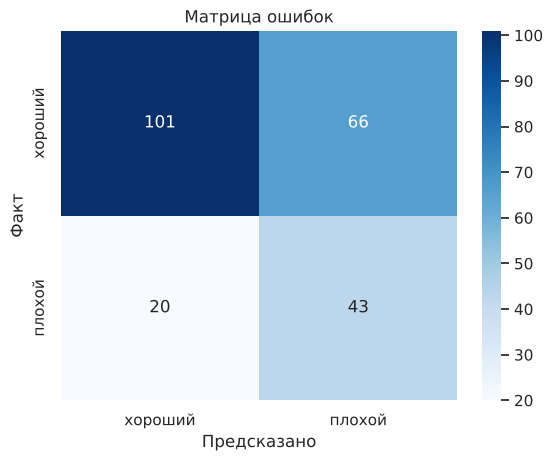

In [32]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = pd.Series({
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba),
})
print(metrics.round(3))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['хороший', 'плохой'], yticklabels=['хороший', 'плохой'])
plt.xlabel('Предсказано')
plt.ylabel('Факт')
plt.title('Матрица ошибок')
plt.show()

**Интерпретация метрик качества** (тестовая выборка, 230 заёмщиков):
- **Accuracy ≈ 0.63:** модель верно классифицирует 63% заёмщиков. Это ниже доли большинства (≈ 73%), но accuracy здесь вводит в заблуждение: модель «всегда хороший» даёт 73%, не находя ни одного плохого заёмщика.
- **Recall ≈ 0.68:** модель находит 68% действительно плохих заёмщиков. Для банка это главная метрика, потому что пропущенный плохой заёмщик стоит дороже всего.
- **Precision ≈ 0.39:** из заёмщиков, которых модель назвала плохими, плохими оказались только 39% — много «ложных тревог».
- **F1 ≈ 0.50:** баланс precision и recall средний.
- **ROC-AUC ≈ 0.68:** модель ранжирует заёмщиков лучше случайного угадывания (0.5), но качество умеренное — ожидаемо, учитывая слабые корреляции признаков с target.

## Тестирование гипотез

Уровень значимости во всех тестах α = 0.05. Используем очищенные данные `df_iqr` в исходных единицах измерения (без масштабирования).

### Тест Шапиро–Уилка (проверка нормальности)

**Формулировка:** проверяем, распределены ли нормально возраст, сумма и срок кредита. От этого зависит выбор параметрического или непараметрического теста.

- H₀: признак распределён нормально
- H₁: распределение признака отличается от нормального

In [33]:
for col in num_cols:
    stat, p = stats.shapiro(df_iqr[col])
    print(f'{col}: W = {stat:.3f}, p-value = {p:.2e}')

Age: W = 0.916, p-value = 3.52e-22
Credit amount: W = 0.840, p-value = 2.41e-29
Duration: W = 0.932, p-value = 4.94e-20


**Интерпретация:**
- У всех трёх признаков p-value < 0.05 → H₀ отвергаем: ни один признак не распределён нормально.
- Для тестов о средних это не критично: выборка большая (n = 917), и по ЦПТ выборочное среднее распределено приблизительно нормально. Для сравнения групп по `Duration` дополнительно используем непараметрический тест Манна–Уитни.

### 1. z-тест для среднего

**Формулировка:** хотим проверить гипотезу о том, что средняя сумма кредита равна 3000 марок, если считать, что выборочная дисперсия равна дисперсии генеральной совокупности.

- H₀: μ = 3000
- H₁: μ ≠ 3000

In [34]:
z_stat, p = ztest(df_iqr['Credit amount'], value=3000, alternative='two-sided')
print(f'Выборочное среднее = {df_iqr["Credit amount"].mean():.1f}')
print(f'z = {z_stat:.3f}, p-value = {p:.4f}')

Выборочное среднее = 2776.1
z = -3.268, p-value = 0.0011


**Интерпретация:**
- p-value ≈ 0.001 < 0.05 → H₀ отвергаем.
- Средняя сумма кредита статистически значимо отличается от 3000 марок: выборочное среднее ≈ 2776, z < 0, то есть средняя сумма меньше 3000.

### 2. Одновыборочный t-тест

**Формулировка:** хотим проверить гипотезу о том, что средний возраст заёмщика равен 35 годам; дисперсия генеральной совокупности неизвестна.

- H₀: μ = 35
- H₁: μ ≠ 35

In [35]:
t_stat, p = stats.ttest_1samp(df_iqr['Age'], popmean=35)
print(f't = {t_stat:.3f}, p-value = {p:.4f}')

t = 1.249, p-value = 0.2120


**Интерпретация:**
- p-value ≈ 0.21 > 0.05 → нет оснований отвергнуть H₀.
- Данные не противоречат тому, что средний возраст заёмщика равен 35 годам (выборочное среднее ≈ 35.5).

### 3. t-тест для двух независимых выборок

**Формулировка:** хотим проверить гипотезу о том, что средняя сумма кредита у плохих и хороших заёмщиков одинакова. Выборки независимы: каждый заёмщик относится только к одной группе.

- H₀: μ_плохие = μ_хорошие
- H₁: μ_плохие ≠ μ_хорошие

In [36]:
good = df_iqr[df_iqr['target'] == 1]
bad = df_iqr[df_iqr['target'] == 2]

lev_stat, lev_p = stats.levene(bad['Credit amount'], good['Credit amount'])
print(f'Тест Левена на равенство дисперсий: p-value = {lev_p:.4f}')

t_stat, p = stats.ttest_ind(bad['Credit amount'], good['Credit amount'], equal_var=False)
print(f't = {t_stat:.3f}, p-value = {p:.4f}')

Тест Левена на равенство дисперсий: p-value = 0.0159


t = 1.466, p-value = 0.1433


**Интерпретация:**
- По тесту Левена (p ≈ 0.016 < 0.05) дисперсии в группах различаются, поэтому используем t-тест Уэлча (`equal_var=False`).
- p-value ≈ 0.14 > 0.05 → нет оснований отвергнуть H₀: средняя сумма кредита у плохих (≈ 2955) и хороших (≈ 2709) заёмщиков статистически значимо не различается.

### 4. Парный t-тест

**Формулировка:** парный t-тест сравнивает два измерения **одних и тех же** объектов (например, сумму долга заёмщика до и после реструктуризации).

- H₀: μ_d = 0 (средняя разность пар равна нулю)
- H₁: μ_d ≠ 0

**Интерпретация:** в наших данных у каждого заёмщика каждый признак измерен **один раз**, связанных пар наблюдений нет. Предпосылка парного теста не выполняется, поэтому применить его к этим данным нельзя.

### 5. z-тест для доли

**Формулировка:** хотим проверить гипотезу о том, что доля плохих заёмщиков в генеральной совокупности равна 30% (такую долю заявляют составители исходного датасета).

- H₀: p = 0.3
- H₁: p ≠ 0.3

In [37]:
count = (df_iqr['target'] == 2).sum()
nobs = len(df_iqr)
z_stat, p = proportions_ztest(count, nobs, value=0.3)
print(f'Выборочная доля = {count / nobs:.3f}')
print(f'z = {z_stat:.3f}, p-value = {p:.4f}')

Выборочная доля = 0.273
z = -1.861, p-value = 0.0627


**Интерпретация:**
- p-value ≈ 0.063 > 0.05 → нет оснований отвергнуть H₀.
- Выборочная доля плохих заёмщиков (≈ 27.3%) статистически значимо не отличается от 30%. Доля ниже исходных 30%, потому что при удалении выбросов исключены 83 крупных и длинных кредита, из которых ≈ 60% — плохие.

### 6. Хи-квадрат на независимость

**Формулировка:** хотим проверить, связаны ли тип жилья (`Housing`) и кредитный риск (`target`).

- H₀: `Housing` и `target` независимы
- H₁: `Housing` и `target` зависимы

In [38]:
ct = pd.crosstab(df_iqr['Housing'], df_iqr['target'])
chi2, p, dof, expected = stats.chi2_contingency(ct)
print(ct)
print(f'chi2 = {chi2:.3f}, dof = {dof}, p-value = {p:.4f}')
print('Минимальная ожидаемая частота:', expected.min().round(1))

target     1    2
Housing          
free      54   25
own      505  164
rent     108   61
chi2 = 9.962, dof = 2, p-value = 0.0069
Минимальная ожидаемая частота: 21.5


**Интерпретация:**
- Предпосылка выполнена: все ожидаемые частоты больше 5 (минимальная ≈ 21.5).
- p-value ≈ 0.007 < 0.05 → H₀ отвергаем: тип жилья и кредитный риск связаны.
- Среди арендаторов доля плохих заёмщиков ≈ 36%, среди владельцев жилья — ≈ 25%.

### 7. Тест Манна–Уитни

**Формулировка:** `Duration` распределён не нормально (тест Шапиро–Уилка), поэтому сравниваем сроки кредита в двух группах непараметрическим тестом. Проверяем, что у плохих заёмщиков сроки кредита, как правило, длиннее, чем у хороших.

- H₀: распределения `Duration` у плохих и хороших заёмщиков одинаковы
- H₁: значения `Duration` у плохих заёмщиков стохастически больше, чем у хороших

In [39]:
u_stat, p = stats.mannwhitneyu(bad['Duration'], good['Duration'], alternative='greater')
print(f'U = {u_stat:.1f}, p-value = {p:.2e}')

U = 100216.5, p-value = 9.66e-07


**Интерпретация:**
- p-value ≈ 9.7·10⁻⁷ < 0.05 → H₀ отвергаем.
- У плохих заёмщиков сроки кредита статистически значимо длиннее (медиана 18 мес. против 15). Это согласуется с корреляционным анализом и с положительным коэффициентом `Duration` в регрессии.

## Общий вывод

- После очистки (пропуски → мода, удаление выбросов методами 3σ и 1.5·IQR) осталось 917 заёмщиков, из них ≈ 27% плохих.
- Риск невозврата сильнее всего связан со сроком кредита (чем дольше, тем выше риск), возрастом (молодые рискованнее) и сбережениями (чем больше, тем ниже риск); тип жилья тоже связан с риском (тест хи-квадрат).
- Сумма кредита после удаления выбросов почти не отличает хороших заёмщиков от плохих (t-тест Уэлча, корреляция ≈ 0).
- Логистическая регрессия находит ≈ 68% плохих заёмщиков при ROC-AUC ≈ 0.68: качество умеренное, потому что все связи признаков с целевой переменной слабые.